# CosMx human liver

This notebook is used to tokenize the CosMx human lung dataset and generate dataset statistics for figures in nicheformer. 

## Imports and definitions

In [1]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import math
import numba
from scipy.sparse import issparse
from sklearn.utils import sparsefuncs

import pyarrow.parquet as pq
import pyarrow
from os.path import join
from tqdm import tqdm


# plotting imports
import seaborn as sns

In [2]:
modality_dict = {
    'dissociated': 3,
    'spatial': 4,}

specie_dict = {
    'human': 5,
    'Homo sapiens': 5,
    'Mus musculus': 6,
    'mouse': 6,}

technology_dict = {
    "merfish": 7,
    "MERFISH": 7,
    "cosmx": 8,
    "NanoString digital spatial profiling": 8,
    "visium": 9,
    "10x 5' v2": 10,
    "10x 3' v3": 11,
    "10x 3' v2": 12,
    "10x 5' v1": 13,
    "10x 3' v1": 14,
    "10x 3' transcription profiling": 15, 
    "10x transcription profiling": 15,
    "10x 5' transcription profiling": 16,
    "CITE-seq": 17, 
    "Smart-seq v4": 18,
}
niche_label_dict = {
    'Zone_1a/PV': 0,
    'Zone_1b': 1,
    'Zone_2a': 2,
    'Zone_2b': 3,
    'Zone_3a': 4,
    'Zone_3b/CV': 5,
    'interface': 6,
    'non-malignant': 7,
    'tumor': 8,
    'tumor subtype': 9
}
niche_label_healthy_dict = {
    'Zone_1a/PV': 0,
    'Zone_1b': 1,
    'Zone_2a': 2,
    'Zone_2b': 3,
    'Zone_3a': 4,
    'Zone_3b/CV': 5,
}
region_label_dict = {
    'nan': 0
}
author_cell_type_dict = {
    'Antibody.secreting.B.cells': 0,
    'CD3+.alpha.beta.T.cells': 1,
    'Central.venous.LSECs': 2,
    'Cholangiocytes': 3,
    'Erthyroid.cells': 4,
    'Hep': 5,
    'Hep.1': 6, 
    'Hep.3': 7, 
    'Hep.4': 8, 
    'Hep.5': 9, 
    'Hep.6': 10,
    'Inflammatory.macrophages': 11, 
    'Mature.B.cells': 12, 
    'NK.like.cells': 13,
    'Non.inflammatory.macrophages': 14, 
    'NotDet': 15, 
    'Periportal.LSECs': 16,
    'Portal.endothelial.cells': 17, 
    'Stellate.cells': 18,
    'gamma.delta.T.cells.1': 19, 
    'tumor_1': 20, 
    'tumor_2': 21
}

## Paths

In [2]:
BASE_PATH = '/lustre/groups/ml01/projects/2023_nicheformer/data/data_to_tokenize'
DATA_PATH = '/lustre/groups/ml01/projects/2023_nicheformer_data_anna.schaar/spatial/preprocessed/human'
OUT_PATH = '/lustre/groups/ml01/projects/2023_nicheformer_data_anna.schaar/tokenized/nicheformer_downstream/cosmx_liver'
GENE_MAPPER_PATH = '/lustre/groups/ml01/projects/2023_nicheformer_data_anna.schaar/concat'

## Tokenization functions

In [4]:
def sf_normalize(X):
    X = X.copy()
    counts = np.array(X.sum(axis=1))
    # avoid zero devision error
    counts += counts == 0.
    # normalize to 10000. counts
    scaling_factor = 10000. / counts

    if issparse(X):
        sparsefuncs.inplace_row_scale(X, scaling_factor)
    else:
        np.multiply(X, scaling_factor.reshape((-1, 1)), out=X)

    return X

@numba.jit(nopython=True, nogil=True)
def _sub_tokenize_data(x: np.array, max_seq_len: int = -1, aux_tokens: int = 30):
    scores_final = np.empty((x.shape[0], max_seq_len if max_seq_len > 0 else x.shape[1]))
    for i, cell in enumerate(x):
        nonzero_mask = np.nonzero(cell)[0]    
        sorted_indices = nonzero_mask[np.argsort(-cell[nonzero_mask])][:max_seq_len] 
        sorted_indices = sorted_indices + aux_tokens # we reserve some tokens for padding etc (just in case)
        if max_seq_len:
            scores = np.zeros(max_seq_len, dtype=np.int32)
        else:
            scores = np.zeros_like(cell, dtype=np.int32)
        scores[:len(sorted_indices)] = sorted_indices.astype(np.int32)
        
        scores_final[i, :] = scores
        
    return scores_final


def tokenize_data(x: np.array, median_counts_per_gene: np.array, max_seq_len: int = None):
    """Tokenize the input gene vector to a vector of 32-bit integers."""

    x = np.nan_to_num(x) # is NaN values, fill with 0s
    x = sf_normalize(x)
    median_counts_per_gene += median_counts_per_gene == 0
    out = x / median_counts_per_gene.reshape((1, -1))

    scores_final = _sub_tokenize_data(out, 4096, 30)

    return scores_final.astype('i4')

## Loading model with right gene ordering

In [5]:
model = sc.read_h5ad(
    f"{BASE_PATH}/model.h5ad"
)

## Technology mean

In [6]:
cosmx_mean = np.load(
    f"{BASE_PATH}/cosmx_mean_script.npy")

In [7]:
cosmx_mean = np.nan_to_num(cosmx_mean)
rounded_values = np.where((cosmx_mean % 1) >= 0.5, np.ceil(cosmx_mean), np.floor(cosmx_mean))
cosmx_mean = np.where(cosmx_mean == 0, 1, rounded_values)
cosmx_mean

array([1., 1., 1., ..., 1., 1., 1.])

## Loading CosMx human liver data

In [ ]:
cosmx = sc.read_h5ad(f"{DATA_PATH}/nanostring_cosmx_human_liver.h5ad")
cosmx

In [ ]:
np.unique(cosmx.obs.author_cell_type)

### Data summary plots and figure panels

In [6]:
# copying the data to ensure original one stays clean
cosmx_figs = cosmx.copy()

In [7]:
cosmx_figs.obsm['spatial'] = np.array(cosmx_figs.obs[['x_slide_mm', 'y_slide_mm']])

In [8]:
cosmx_figs.obs['sample_name_test'] = [str(x.split('_')[1]) for x in list(cosmx_figs.obs.index)]

In [13]:
cosmx_figs.uns['niche_colors'] = ['#204B57', '#197BBD', '#C2B8B2', '#8A716A', '#B7A14D', '#E3D12F']

/home/icb/anna.schaar/miniconda3/envs/nf-data/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


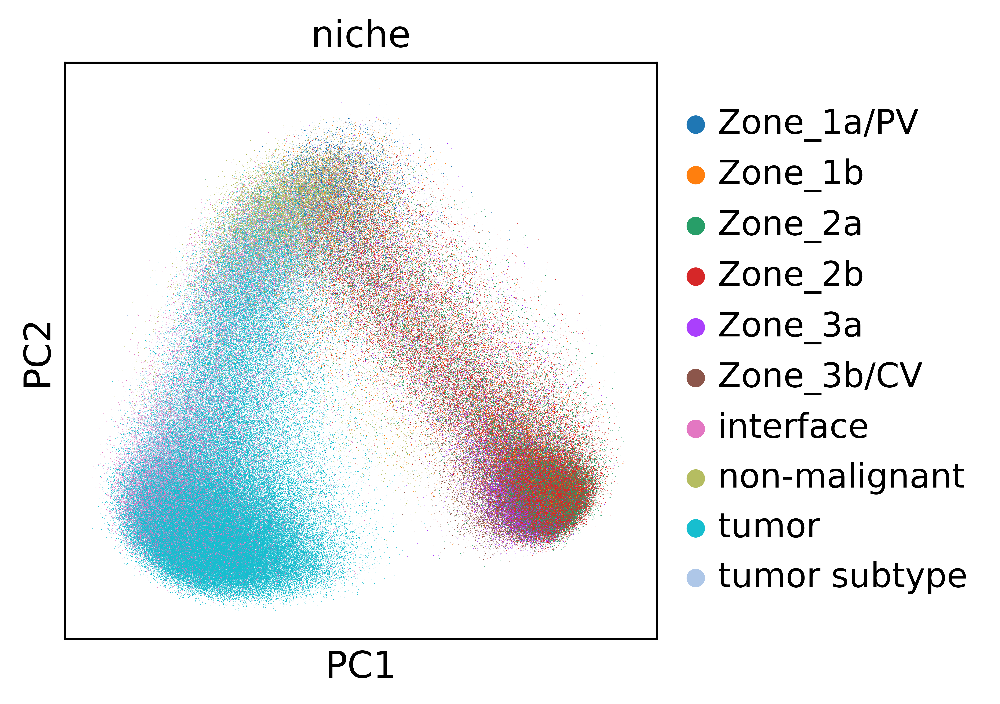

In [85]:
sc.pl.pca(cosmx_figs, color='niche')

In [157]:
color_mapper = {}
for i, ct in enumerate(np.unique(cosmx_figs.obs['author_cell_type'])):
    color_mapper[ct] = cosmx_figs.uns['author_cell_type_colors'][i]

In [158]:
color_mapper

{'Antibody.secreting.B.cells': '#023fa5',
 'CD3+.alpha.beta.T.cells': '#7d87b9',
 'Central.venous.LSECs': '#bec1d4',
 'Cholangiocytes': '#d6bcc0',
 'Erthyroid.cells': '#bb7784',
 'Hep': '#8e063b',
 'Hep.1': '#4a6fe3',
 'Hep.3': '#8595e1',
 'Hep.4': '#b5bbe3',
 'Hep.5': '#e6afb9',
 'Hep.6': '#e07b91',
 'Inflammatory.macrophages': '#d33f6a',
 'Mature.B.cells': '#11c638',
 'NK.like.cells': '#8dd593',
 'Non.inflammatory.macrophages': '#c6dec7',
 'NotDet': '#ead3c6',
 'Periportal.LSECs': '#f0b98d',
 'Portal.endothelial.cells': '#ef9708',
 'Stellate.cells': '#0fcfc0',
 'gamma.delta.T.cells.1': '#9cded6',
 'tumor_1': '#d5eae7',
 'tumor_2': '#f3e1eb'}

In [30]:
healthy = cosmx_figs[cosmx_figs.obs['sample_name_test']=='1']

In [18]:
healthy.uns['niche_colors'] = ['#204B57', '#197BBD', '#C2B8B2', '#8A716A', '#D34949', '#9F0B0B']

In [18]:
healthy.uns['nicheformer_split_colors'] = ['#2F4E6D', 'lightgrey']

/tmp/ipykernel_179337/3915021273.py:1: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  healthy.uns['nicheformer_split_colors'] = ['#2F4E6D', 'lightgrey']


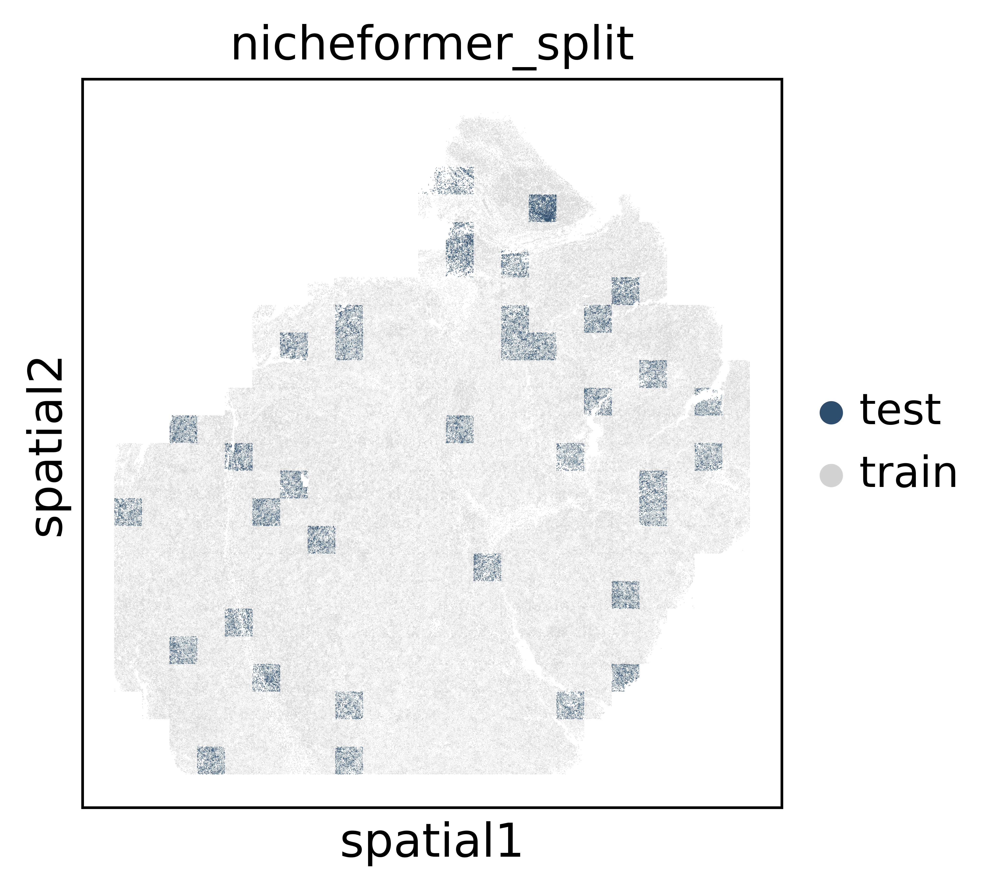

In [19]:
sc.settings.set_figure_params(dpi=500, facecolor='white')
sc.pl.spatial(healthy, spot_size=0.01, color='nicheformer_split')

In [154]:
df = pd.DataFrame(pd.value_counts(cosmx_figs[cosmx_figs.obs.nicheformer_split == 'test'].obs.author_cell_type)).reset_index()

In [103]:
niche_color_mapper = {
    'Zone_1a/PV':'#204B57', 
    'Zone_1b':'#197BBD',
    'Zone_2a':'#C2B8B2', 
    'Zone_2b':'#8A716A', 
    'Zone_3a':'#D34949', 
    'Zone_3b/CV':'#9F0B0B'
}

In [155]:
df

,index,author_cell_type
0,tumor_1,34999
1,Hep.4,11168
2,Hep.5,8382
3,CD3+.alpha.beta.T.cells,3739
4,tumor_2,3504
5,Inflammatory.macrophages,2390
6,Stellate.cells,2386
7,Periportal.LSECs,1921
8,Non.inflammatory.macrophages,1808
9,Hep.3,1685


In [159]:
df['color'] = [color_mapper[x] for x in df['index']]

In [160]:
df['ct_clean'] = [x.replace('.', ' ').replace('_', ' ') for x in df['index']]

In [161]:
color_mapper = {}
for i,x in enumerate(list(df['ct_clean'])):
    color_mapper[x] = list(df['color'])[i]

In [162]:
df

,index,author_cell_type,color,ct_clean
0,tumor_1,34999,#d5eae7,tumor 1
1,Hep.4,11168,#b5bbe3,Hep 4
2,Hep.5,8382,#e6afb9,Hep 5
3,CD3+.alpha.beta.T.cells,3739,#7d87b9,CD3+ alpha beta T cells
4,tumor_2,3504,#f3e1eb,tumor 2
5,Inflammatory.macrophages,2390,#d33f6a,Inflammatory macrophages
6,Stellate.cells,2386,#0fcfc0,Stellate cells
7,Periportal.LSECs,1921,#f0b98d,Periportal LSECs
8,Non.inflammatory.macrophages,1808,#c6dec7,Non inflammatory macrophages
9,Hep.3,1685,#8595e1,Hep 3


In [148]:
df = df.iloc[:-1,:]

In [163]:
order_mapper = {}
for i, x in enumerate(list(df['ct_clean'])):
    order_mapper[x] = list(df['author_cell_type'])[i]

In [164]:
color_mapper

{'tumor 1': '#d5eae7',
 'Hep 4': '#b5bbe3',
 'Hep 5': '#e6afb9',
 'CD3+ alpha beta T cells': '#7d87b9',
 'tumor 2': '#f3e1eb',
 'Inflammatory macrophages': '#d33f6a',
 'Stellate cells': '#0fcfc0',
 'Periportal LSECs': '#f0b98d',
 'Non inflammatory macrophages': '#c6dec7',
 'Hep 3': '#8595e1',
 'Hep 1': '#4a6fe3',
 'Mature B cells': '#11c638',
 'Hep 6': '#e07b91',
 'Cholangiocytes': '#d6bcc0',
 'Central venous LSECs': '#bec1d4',
 'gamma delta T cells 1': '#9cded6',
 'Antibody secreting B cells': '#023fa5',
 'NK like cells': '#8dd593',
 'Hep': '#8e063b',
 'Portal endothelial cells': '#ef9708',
 'Erthyroid cells': '#bb7784'}

In [152]:
# do not re-run for test
clean_names = list(df['ct_clean'])

In [165]:
clean_values = []
clean_color = []
for x in clean_names:
    clean_values.append(order_mapper[x])
    clean_color.append(color_mapper[x])

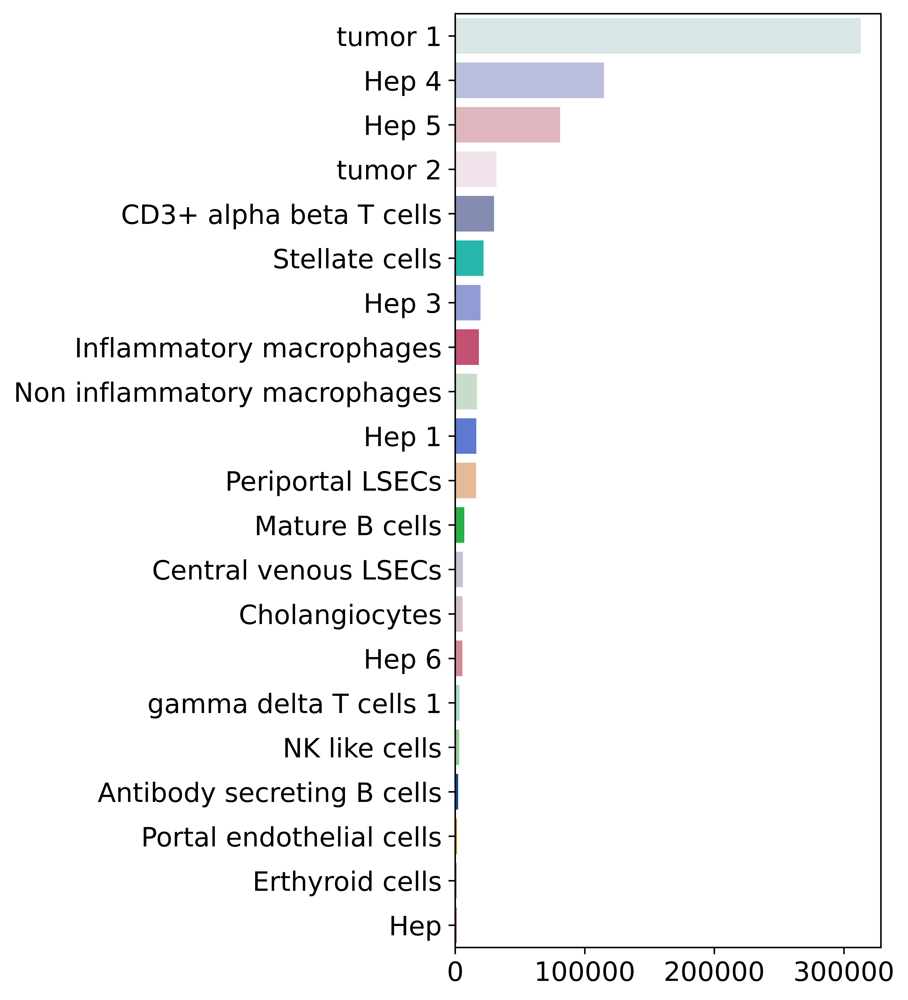

In [151]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1, figsize=(4,9))
sns.barplot(
    y= clean_names, 
    x=clean_values, 
    palette=list(df['color']), 
    ax=ax
)
ax.grid(False)
plt.show()

In [ ]:
sc.pl.spatial(healthy[healthy_test.obs['library_key']==img_key], spot_size=0.01, color='niche')

In [20]:
np.unique(cosmx_figs[cosmx_figs.obs['sample_name_test']=='1'].obs.library_key)

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  64,  65,  66,
        67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,  79,
        80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,  92,
        93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104, 105,
       106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118,
       119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131,
       132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144,
       145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157,
       158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170,
       171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 18

In [16]:
healthy = cosmx_figs[cosmx_figs.obs['sample_name_test']=='1']

In [25]:
healthy_test = healthy[healthy.obs['nicheformer_split']=='test']

In [27]:
np.unique(healthy_test.obs.library_key)

array([  2,   7,  38,  46,  53,  66,  69,  91, 125, 141, 156, 172, 177,
       191, 201, 214, 222, 234, 239, 241, 251, 275, 279, 295, 302])

In [22]:
logits = np.load('/lustre/groups/ml01/projects/2023_nicheformer/predictions_newmean/healthy_liver/niche_classification/niche_linear_False_newmean.npy')
true_labels = np.load('/lustre/groups/ml01/projects/2023_nicheformer/predictions_newmean/healthy_liver/niche_classification/label_niche_linear_False_newmean.npy')
predicted_labels = logits.argmax(axis=1)

In [48]:
metadata = pd.read_csv("/lustre/groups/ml01/projects/2023_nicheformer/predictions_newmean/healthy_liver/embeddings/metadata_test_new_mean_final_3.csv")
test_indices = np.load('/lustre/groups/ml01/projects/2023_nicheformer/predictions_newmean/healthy_liver/niche_classification/test_indices.npy')

In [54]:
healthy_test = healthy_test[test_indices,:].copy()

In [55]:
healthy_test.obs['predicted_labels'] = predicted_labels
healthy_test.obs['true_labels']  = true_labels

In [56]:
healthy_test.obs['predicted_labels'] = healthy_test.obs['predicted_labels'].astype('category')
healthy_test.obs['true_labels'] = healthy_test.obs['true_labels'].astype('category')

In [44]:
healthy_test.obs.niche

c_1_125_548     Zone_2a
c_1_125_748     Zone_2b
c_1_125_815     Zone_2b
c_1_141_1056    Zone_2a
c_1_141_1061    Zone_2b
                 ...   
c_1_91_994      Zone_2b
c_1_91_995      Zone_2b
c_1_91_996      Zone_2a
c_1_91_998      Zone_2b
c_1_91_999      Zone_2a
Name: niche, Length: 29458, dtype: category
Categories (6, object): ['Zone_1a/PV', 'Zone_1b', 'Zone_2a', 'Zone_2b', 'Zone_3a', 'Zone_3b/CV']

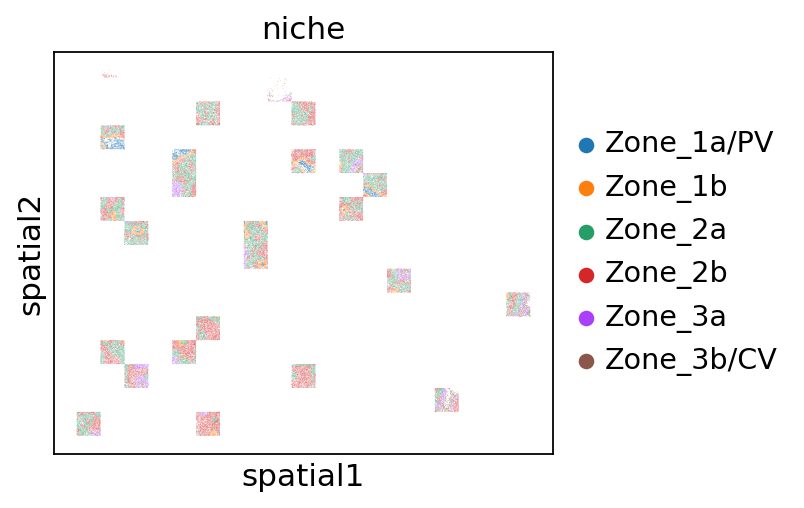

In [58]:
sc.pl.spatial(healthy_test, spot_size=0.01, color='niche')

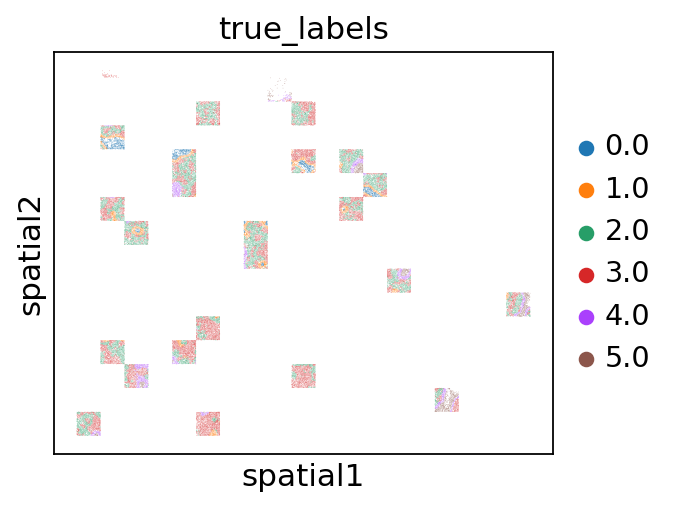

In [59]:
 sc.pl.spatial(healthy_test, spot_size=0.01, color='true_labels')

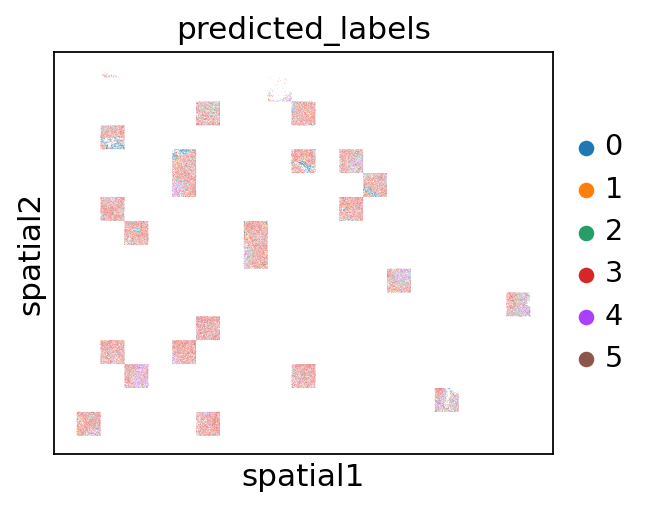

In [60]:
 sc.pl.spatial(healthy_test, spot_size=0.01, color='predicted_labels')

46


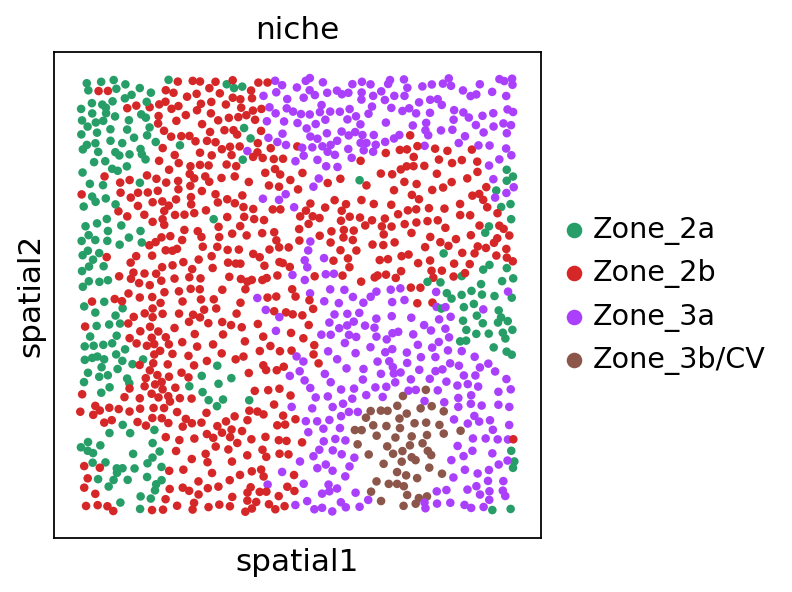

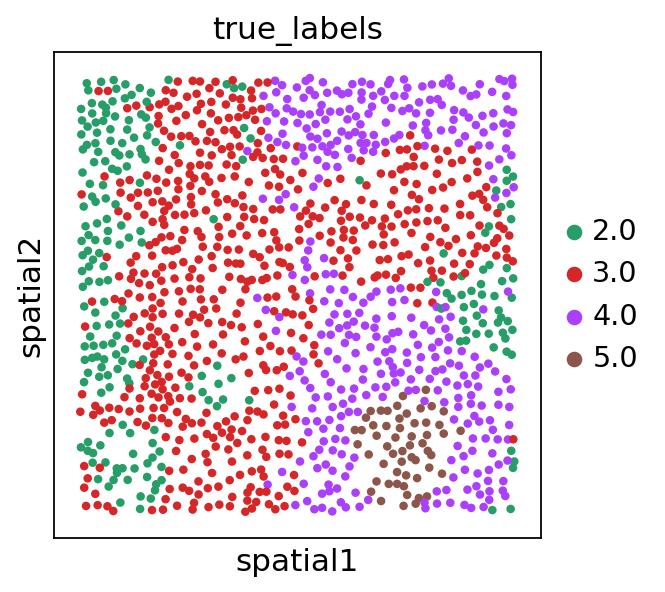

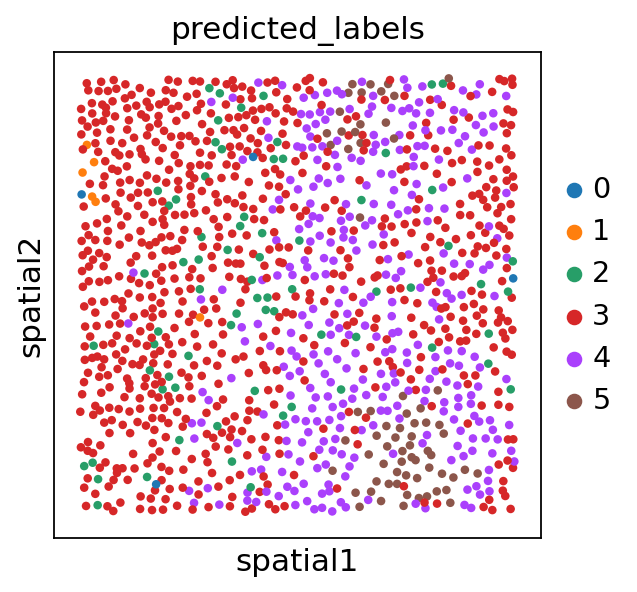

172


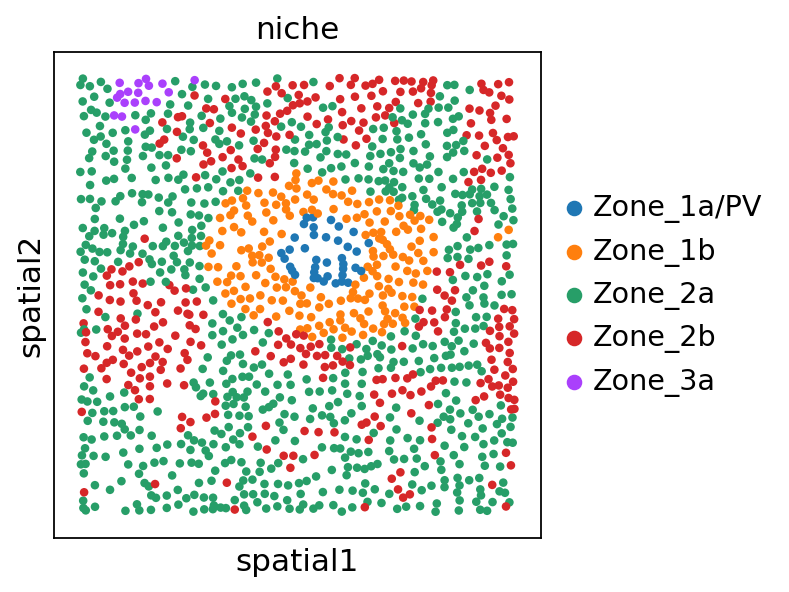

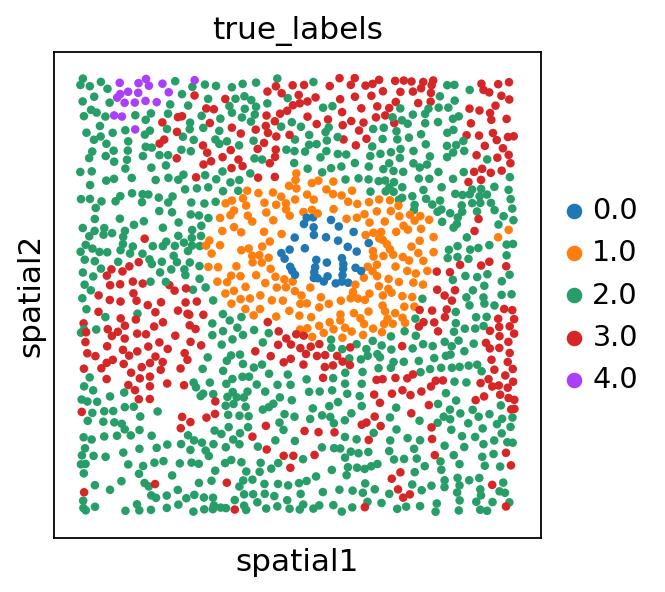

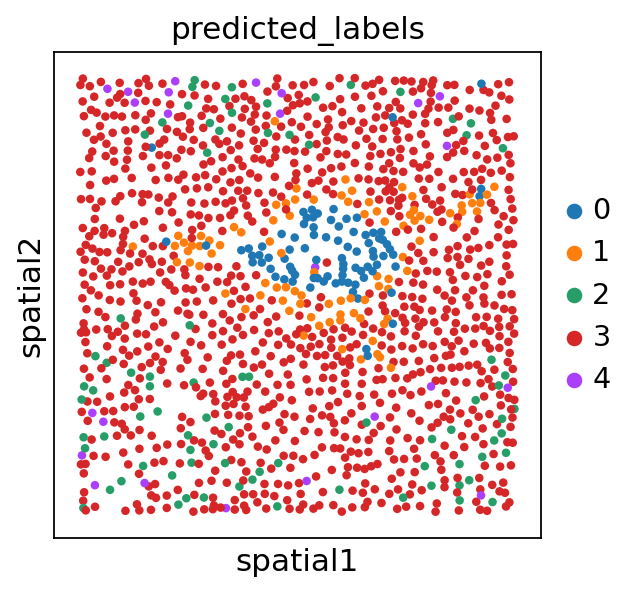

In [61]:
sc.settings.set_figure_params(dpi=80, facecolor='white')
for img_key in [46, 172]:
    print(img_key)
    sc.pl.spatial(healthy_test[healthy_test.obs['library_key']==img_key], spot_size=0.01, color='niche')
    sc.pl.spatial(healthy_test[healthy_test.obs['library_key']==img_key], spot_size=0.01, color='true_labels')
    sc.pl.spatial(healthy_test[healthy_test.obs['library_key']==img_key], spot_size=0.01, color='predicted_labels')

In [30]:
a = cosmx_figs.obs['sample_name_test']=='1'
b = cosmx_figs.obs['nicheformer_split']=='test'
pd.value_counts(cosmx_figs[a&b,:].obs.niche)

Zone_2b       12567
Zone_2a       10479
Zone_1b        2126
Zone_3a        1726
Zone_1a/PV     1476
Zone_3b/CV     1084
Name: niche, dtype: int64

In [31]:
a = cosmx_figs.obs['sample_name_test']=='1'
b = cosmx_figs.obs['nicheformer_split']=='train'
pd.value_counts(cosmx_figs[a&b,:].obs.niche)

Zone_2b       114373
Zone_2a       101804
Zone_3a        31684
Zone_1b        24434
Zone_3b/CV     19093
Zone_1a/PV     12031
Name: niche, dtype: int64

In [ ]:
sc.settings.set_figure_params(dpi=500, facecolor='white')
sc.pl.spatial(cosmx_figs[cosmx_figs.obs['sample_name_test']=='2'], spot_size=0.01, color='author_cell_type')

/home/icb/anna.schaar/miniconda3/envs/nf-data/lib/python3.9/site-packages/anndata/_core/anndata.py:1292: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


/home/icb/anna.schaar/miniconda3/envs/nf-data/lib/python3.9/site-packages/anndata/_core/anndata.py:1292: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


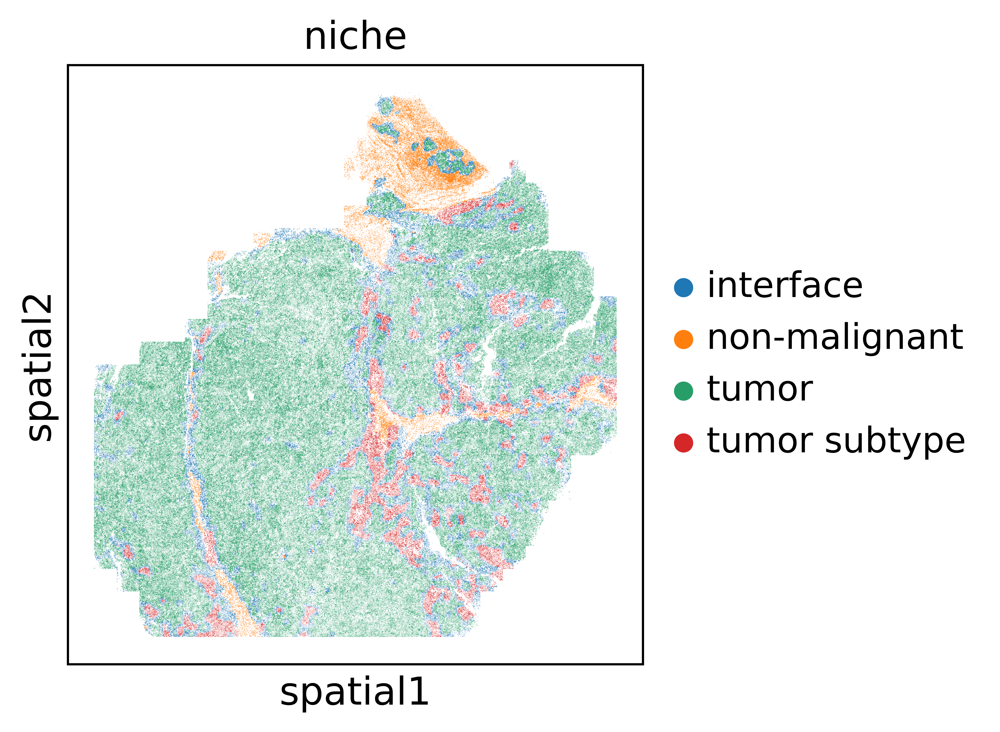

In [28]:
sc.settings.set_figure_params(dpi=500, facecolor='white')
sc.pl.spatial(cosmx_figs[cosmx_figs.obs['sample_name_test']=='2'], spot_size=0.01, color='niche')

In [53]:
cosmx.obs['sample_name_test'] = [str(x.split('_')[1]) for x in list(cosmx.obs.index)]

In [54]:
cosmx.obs['sample_name_test'] = cosmx.obs['sample_name_test'].astype("category")

In [55]:
cosmx.obsm['spatial'] = np.array(cosmx.obs[['x_slide_mm', 'y_slide_mm']])

In [57]:
sq.gr.spatial_neighbors(cosmx, radius=0.027, coord_type='generic', library_key='sample_name_test')

In [59]:
cosmx.obs = cosmx.obs.reset_index()

In [60]:
np.random.seed(0)
test_nodes = np.random.choice(
    a=list(cosmx.obs.index), 
    size=np.int(cosmx.shape[0] * 0.1), 
    replace=False
)
test_nodes = [np.int(x) for x in test_nodes]
split = ['train' for x in list(cosmx.obs.index)]
for i in test_nodes:
    split[i] = 'test'
cosmx.obs['nicheformer_split_densities'] = split

/tmp/ipykernel_1820534/4281072182.py:4: DeprecationWarning: `np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  size=np.int(cosmx.shape[0] * 0.1),
/tmp/ipykernel_1820534/4281072182.py:7: DeprecationWarning: `np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1

In [65]:
EMBED_PATH = "/lustre/groups/ml01/projects/2023_nicheformer/predictions_newmean/liver/embeddings"
adatas = []
for split in ['train', 'test']:
    temp_adata = cosmx[cosmx.obs.nicheformer_split == split].copy()
    temp_adata.obsm['X_nicheformer'] = np.load(f"{EMBED_PATH}/embeddings_{split}_new_mean_final_1.npy")
    adatas.append(temp_adata)

In [70]:
import anndata as ad
adata_densities = ad.AnnData.concatenate(adatas[0], adatas[1])

/tmp/ipykernel_1820534/2093421760.py:2: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata_densities = ad.AnnData.concatenate(adatas[0], adatas[1])


In [71]:
adata_densities

AnnData object with n_obs × n_vars = 793318 × 999
    obs: 'index', 'RNA_pca_cluster_default', 'RNA_pca_cluster_default.1', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'nCount_negprobes', 'nFeature_negprobes', 'nCount_falsecode', 'nFeature_falsecode', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CK8.18', 'Max.CK8.18', 'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'cell_id', 'assay_type', 'Run_name', 'slide_ID_numeric', 'Run_Tissue_name', 'Panel', 'Mean.Yellow', 'Max.Yellow', 'Mean.CD298_B2M', 'Max.CD298_B2M', 'cell_ID', 'x_FOV_px', 'y_FOV_px', 'x_slide_mm', 'y_slide_mm', 'propNegative', 'complexity', 'errorCtEstimate', 'percOfDataFromError', 'qcFlagsRNACounts', 'qcFlagsCellCounts', 'qcFlagsCellPropNeg', 'qcFlagsCellComplex', 'qcFlagsCellArea', 'median_negprobes', 'negprobes_quantile_0.9', 'median_RNA', 'RNA_quantile_0.9', 'nCell', 'nCount', 'nCountPerCell', 'nFeaturePerCell', 'propNegativeCellAvg', 'complexityCel

In [72]:
sq.gr.spatial_neighbors(adata_densities, radius=0.027, coord_type='generic', library_key='sample_name_test')

In [73]:
adata_densities.obs['densities'] = np.array(adata_densities.obsp['spatial_connectivities'].sum(axis=1)).flatten()

In [75]:
del adata_densities.obsp

In [13]:
SAVE_PATH = "/lustre/groups/ml01/projects/2023_nicheformer_data_anna.schaar/spatial"
adata_densities = sc.read_h5ad(f"{SAVE_PATH}/cosmx_densities.h5ad")

In [16]:
adata_densities[adata_densities.obs.sample_name_test=='1'].write(f"{SAVE_PATH}/cosmx_only_healthy.h5ad")

In [62]:

embed = []
meta = []
niches = []
for split in ['train', 'test']:
    embed.append(
        np.load(f"{EMBED_PATH}/embeddings_{split}_new_mean_final_1.npy")
    )
    meta_temp = pd.read_csv(f"{EMBED_PATH}/metadata_{split}_new_mean_final_1.csv", index_col=0)
    meta_temp['nicheformer_split'] = split
    meta.append(meta_temp)

In [28]:
import squidpy as sq
healthy = cosmx[cosmx.obs['sample_name_test']=='1'].copy()
sq.gr.spatial_neighbors(healthy, radius=0.027, coord_type='generic')

In [46]:
import matplotlib.colors
cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["white",'lightgrey', "#2F4E6D", 'black'])

In [40]:
healthy.obs['densities'] = np.array(healthy.obsp['spatial_connectivities'].sum(axis=1)).flatten()

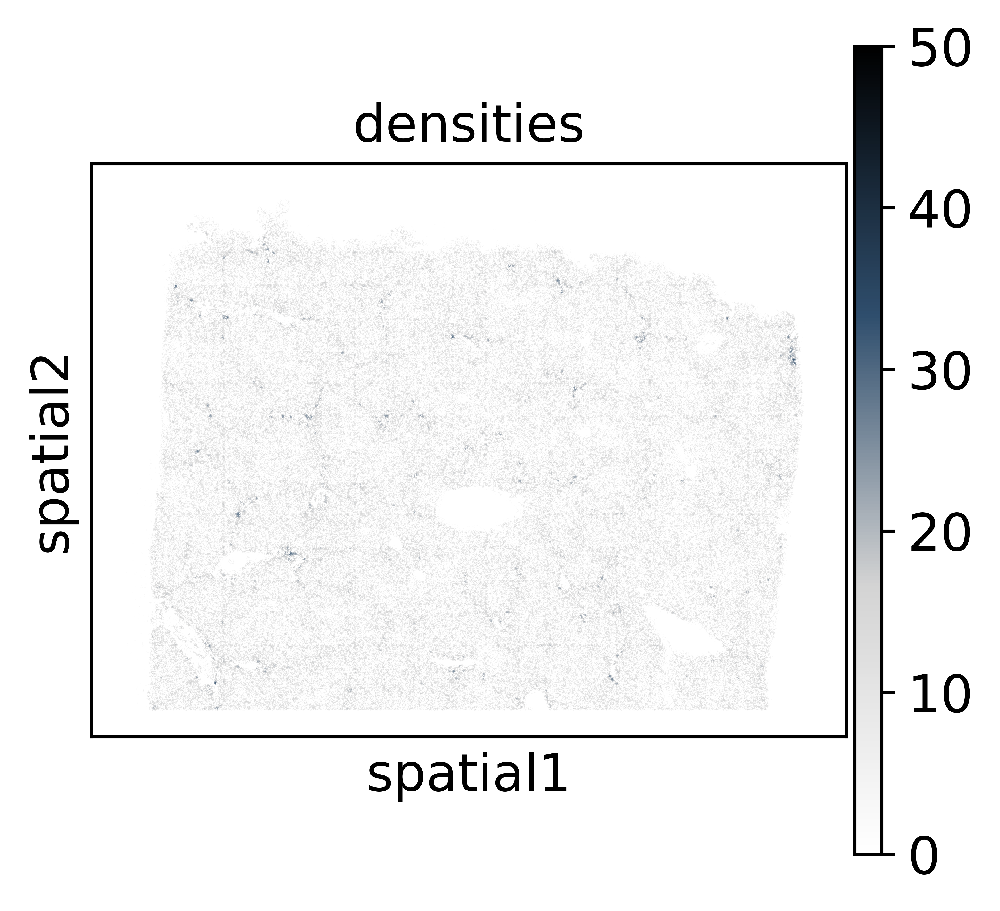

In [47]:
sc.settings.set_figure_params(dpi=500, facecolor='white')
sc.pl.spatial(healthy, spot_size=0.01, color='densities', cmap=cmap, vmax=50)

In [30]:
import squidpy as sq
diseased = cosmx[cosmx.obs['sample_name_test']=='2'].copy()
sq.gr.spatial_neighbors(diseased, radius=0.027, coord_type='generic')
diseased.obsp['spatial_connectivities'].sum(axis=1).mean()

11.943358649642407

In [41]:
diseased.obs['densities'] = np.array(diseased.obsp['spatial_connectivities'].sum(axis=1)).flatten()

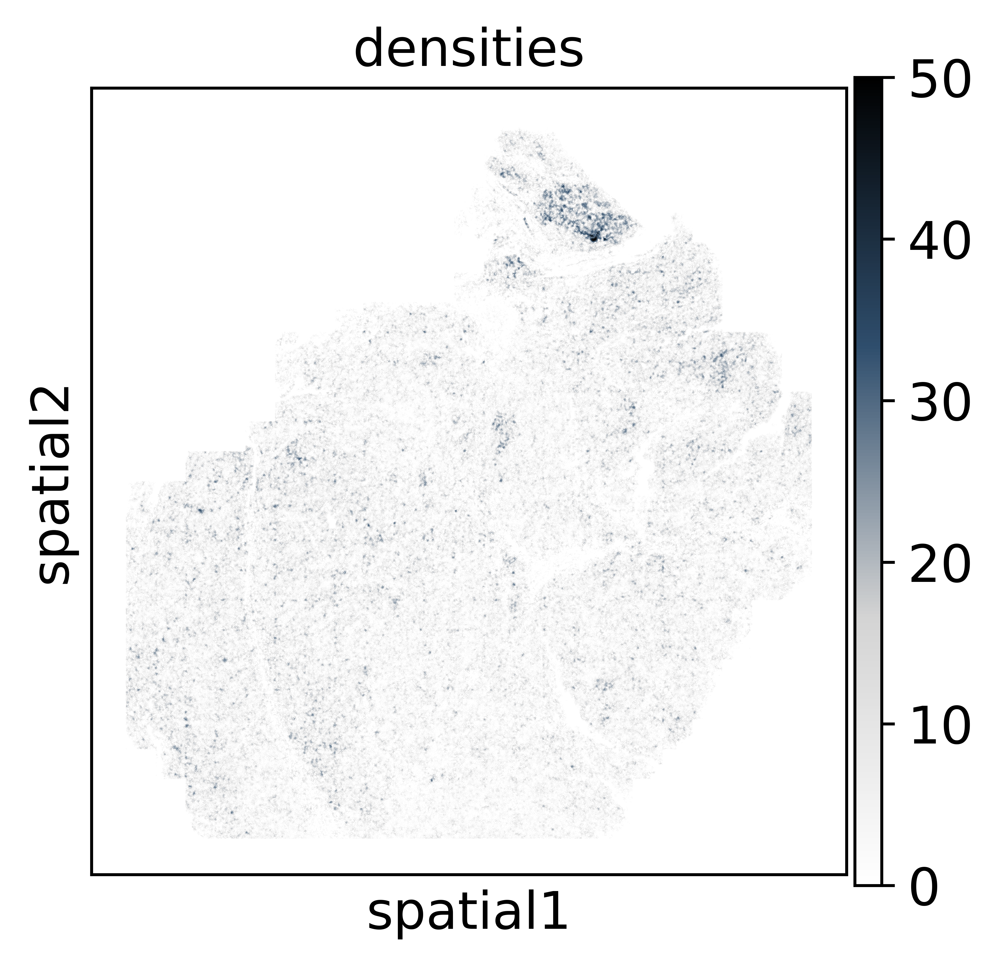

In [48]:
sc.pl.spatial(diseased, spot_size=0.01, color='densities', cmap=cmap, vmax=50)

#### Distribution of neighborhood densities 

In [117]:
sc.settings.set_figure_params(dpi=80, facecolor='white')

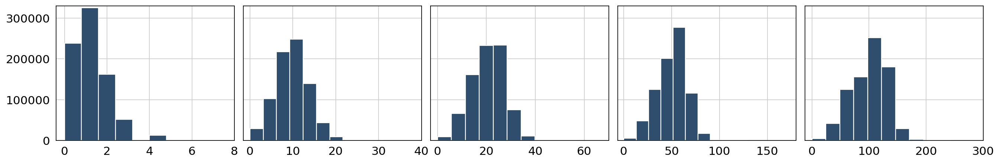

In [118]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 5, figsize=(20,3), sharey=True)
fig.subplots_adjust(wspace=0.05)
limits = {
    0: 8,
    1: 40,
    2: 70,
    3: 180,
    4: 300
}
for idx in np.arange(5):
    ax[idx].hist(
        x=np.array(cosmx_figs.obsm[f"X_niche_{idx}"].sum(axis=1)),
        color='#2f4e6d', bins=10
    )
    ax[idx].set_ylim(top=330000)
    ax[idx].set_xlim(right=limits[idx])

In [170]:
df = pd.DataFrame(
    cosmx_figs.obsm['X_niche_2'].toarray(),
    columns=cosmx_figs.uns['niche']['columns'],
    index=cosmx_figs.uns['niche']['index']
)
df = df.join(cosmx_figs.obs[['nicheformer_split', 'author_cell_type', 'niche']])
#df = df[df['nicheformer_split']=='test']

In [171]:
df = df.drop(columns='author_cell_type')

In [173]:
import matplotlib.pyplot as plt
import matplotlib.colors as clr

cmap = clr.LinearSegmentedColormap.from_list(colors =['white','#2f4e6d', 'black'],name='test', N=256)


<Axes: ylabel='niche'>

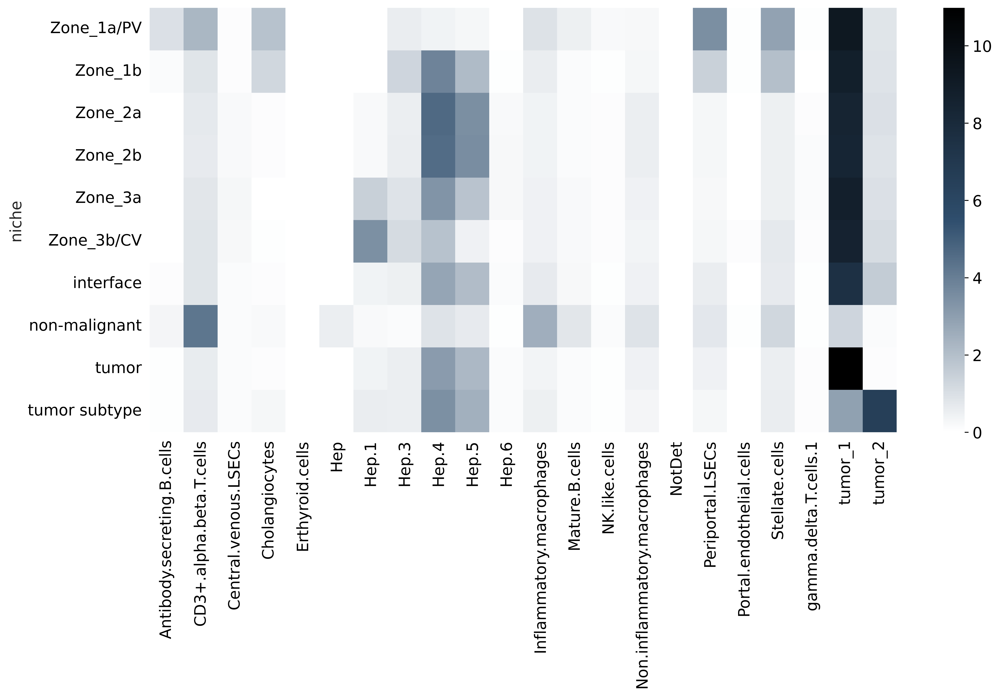

In [174]:
fig, ax = plt.subplots(1, 1, figsize=(15,7))
sns.heatmap(df.groupby('niche').mean(), ax=ax, cmap=cmap)

#### UMAP of niche label

In [101]:
adatas = []
for niche in np.unique(cosmx_figs.obs.niche):
    adatas.append(
        sc.pp.subsample(
            cosmx_figs[cosmx_figs.obs['niche'] == niche], fraction=0.4, copy=True
        )
    )

In [102]:
cosmx_subsample = ad.concat(adatas)

In [103]:
cosmx_subsample

AnnData object with n_obs × n_vars = 317324 × 999
    obs: 'RNA_pca_cluster_default', 'RNA_pca_cluster_default.1', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'nCount_negprobes', 'nFeature_negprobes', 'nCount_falsecode', 'nFeature_falsecode', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CK8.18', 'Max.CK8.18', 'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'cell_id', 'assay_type', 'Run_name', 'slide_ID_numeric', 'Run_Tissue_name', 'Panel', 'Mean.Yellow', 'Max.Yellow', 'Mean.CD298_B2M', 'Max.CD298_B2M', 'cell_ID', 'x_FOV_px', 'y_FOV_px', 'x_slide_mm', 'y_slide_mm', 'propNegative', 'complexity', 'errorCtEstimate', 'percOfDataFromError', 'qcFlagsRNACounts', 'qcFlagsCellCounts', 'qcFlagsCellPropNeg', 'qcFlagsCellComplex', 'qcFlagsCellArea', 'median_negprobes', 'negprobes_quantile_0.9', 'median_RNA', 'RNA_quantile_0.9', 'nCell', 'nCount', 'nCountPerCell', 'nFeaturePerCell', 'propNegativeCellAvg', 'complexityCellAvg', 'e

In [104]:
cosmx_subsample.X = cosmx_subsample.layers['log1p']
sc.pp.neighbors(cosmx_subsample)
sc.tl.umap(cosmx_subsample)

In [105]:
sc.tl.umap(cosmx_subsample)

In [126]:
sc.settings.set_figure_params(dpi=300, facecolor='white')

In [128]:
cosmx_subsample.uns['niche_colors'] = [
    '#10202e',
    '#113755',
    '#73d0d3',
    '#44a9bb',
    
    '#1581a2',
    '#1c5987',

    '#89c62d',
    '#d9ed92',
    # tumor
    '#284d19',
    '#48884a'
]

/home/icb/anna.schaar/miniconda3/envs/nf-data/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


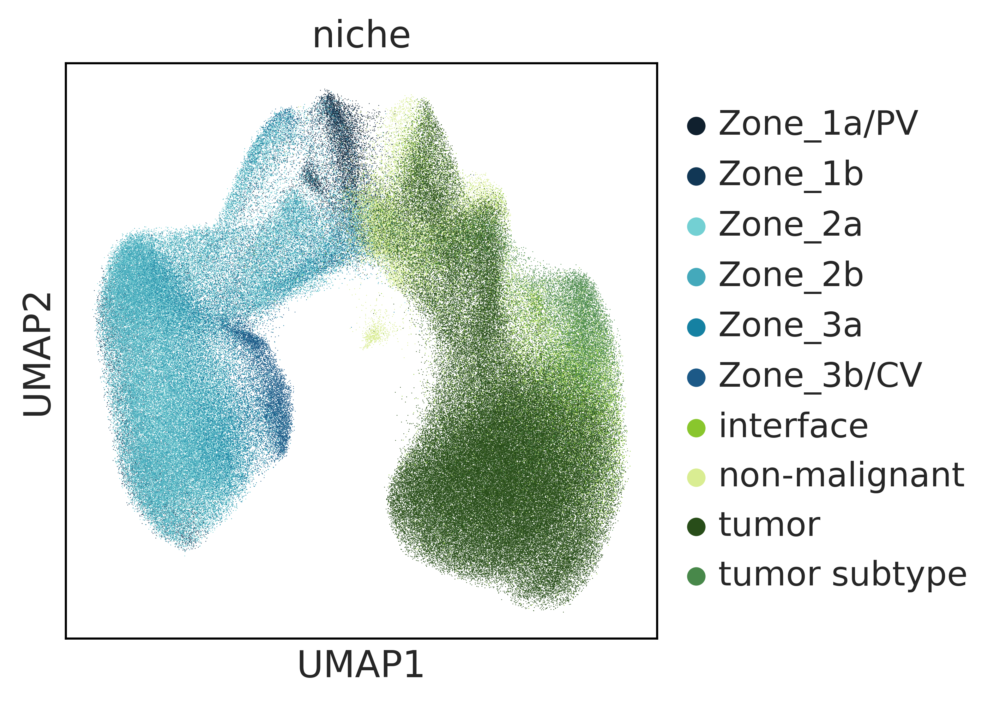

In [129]:
sc.pl.umap(cosmx_subsample, color='niche')

## Concatenation
Next we concatenate the `model` and the `merfish` object to ensure they are in the same order. This ensures we have the same gene ordering in the object.

In [15]:
adata = ad.concat([model, cosmx], join='outer', axis=0)
# dropping the first observation 
cosmx = adata[1:].copy()
# for memory efficiency 
del adata

In [16]:
cosmx.obs = cosmx.obs[
    ['assay', 'organism', 'nicheformer_split', 'batch', 'niche', 'region', 'author_cell_type']
]
cosmx.obs['modality'] = 'spatial'
cosmx.obs['specie'] = cosmx.obs.organism

In [17]:
cosmx.obs.replace({'specie': specie_dict}, inplace=True)
cosmx.obs.replace({'modality': modality_dict}, inplace=True)
cosmx.obs.replace({'assay': technology_dict}, inplace=True)
cosmx.obs.replace({'author_cell_type': author_cell_type_dict}, inplace=True)
cosmx.obs.replace({'niche': niche_label_dict}, inplace=True)
cosmx.obs.replace({'region': region_label_dict}, inplace=True)

## Tokenize train data

We know tokenize the train partition of the dataset. 

In [18]:
SPLIT = 'train'

In [19]:
# subsetting the anndata object
cosmx_split = cosmx[cosmx.obs.nicheformer_split == SPLIT].copy()
# dropping the index as the original index can create issues 
cosmx_split.obs.reset_index(drop=True, inplace=True)
# writing the data
cosmx_split.write(f"{OUT_PATH}/cosmx_human_liver_{SPLIT}_ready_to_tokenize.h5ad")

In [20]:
obs_cosmx_split = cosmx_split.obs
print('n_obs: ', obs_cosmx_split.shape[0])
N_BATCHES = math.ceil(obs_cosmx_split.shape[0] / 10_000)
print('N_BATCHES: ', N_BATCHES)
batch_cosmx_indices = np.array_split(obs_cosmx_split.index, N_BATCHES)
chunk_len = len(batch_cosmx_indices[0])
print('chunk_len: ', chunk_len)

n_obs:  716207
N_BATCHES:  72
chunk_len:  9948


In [21]:
obs_cosmx_split = obs_cosmx_split.reset_index().rename(columns={'index':'idx'})
obs_cosmx_split['idx'] = obs_cosmx_split['idx'].astype('i8')

In [22]:
print(f"Tokenizing {SPLIT}")
for batch in tqdm(range(N_BATCHES)):
    obs_tokens = obs_cosmx_split.iloc[batch*chunk_len:chunk_len*(batch+1)].copy()
    cosmx_tokenized = tokenize_data(cosmx_split.X[batch*chunk_len:chunk_len*(batch+1)], cosmx_mean, 4096)

    obs_tokens = obs_tokens[['assay', 'specie', 'modality', 'idx', 'author_cell_type', 'niche', 'region']]
    # concatenate dataframes
    
    obs_tokens['X'] = [cosmx_tokenized[i, :] for i in range(cosmx_tokenized.shape[0])]
    
    for i in np.arange(5):
        niche = cosmx_split.obsm[f"X_niche_{i}"].toarray()[batch*chunk_len:chunk_len*(batch+1)]
        obs_tokens[f"X_niche_{i}"] = [niche[i, :] for i in range(niche.shape[0])]

    # mix spatial and dissociate data
    obs_tokens = obs_tokens.sample(frac=1)
    
    total_table = pyarrow.Table.from_pandas(obs_tokens)
    
    pq.write_table(total_table, f'{join(OUT_PATH, SPLIT)}/tokens-{batch}.parquet',
                    row_group_size=1024,)

Tokenizing train


100%|███████████████████████████████████████████| 72/72 [03:33<00:00,  2.96s/it]


In [23]:
# checking for the last object whether everything looks accurate 
obs_tokens.head(2)

,assay,specie,modality,idx,author_cell_type,niche,region,X,X_niche_0,X_niche_1,X_niche_2,X_niche_3,X_niche_4
712068,8,5,4,712068,20,8,0,"[5799, 18939, 4741, 8592, 8114, 6173, 17558, 3...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 5.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0, 0.0, 13.0,...","[0.0, 1.0, 2.0, 0.0, 0.0, 0.0, 5.0, 3.0, 31.0,..."
712942,8,5,4,712942,20,8,0,"[17558, 3623, 13558, 11752, 4413, 16224, 18902...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.0, ...","[0.0, 3.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 9.0, ...","[0.0, 3.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 23.0,..."


In [24]:
pd.read_parquet(f'{join(OUT_PATH, SPLIT)}/tokens-{batch}.parquet').head(2)

,assay,specie,modality,idx,author_cell_type,niche,region,X,X_niche_0,X_niche_1,X_niche_2,X_niche_3,X_niche_4
712068,8,5,4,712068,20,8,0,"[5799, 18939, 4741, 8592, 8114, 6173, 17558, 3...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 5.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0, 0.0, 13.0,...","[0.0, 1.0, 2.0, 0.0, 0.0, 0.0, 5.0, 3.0, 31.0,..."
712942,8,5,4,712942,20,8,0,"[17558, 3623, 13558, 11752, 4413, 16224, 18902...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.0, ...","[0.0, 3.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 9.0, ...","[0.0, 3.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 23.0,..."


### Reading for testing
We are reading one parquet file to test whether everything worked.

## Tokenize test data

In [25]:
SPLIT = 'test'

In [26]:
# subsetting the anndata object
cosmx_split = cosmx[cosmx.obs.nicheformer_split == SPLIT].copy()
# dropping the index as the original index can create issues 
cosmx_split.obs.reset_index(drop=True, inplace=True)
# writing the data
cosmx_split.write(f"{OUT_PATH}/cosmx_human_liver_{SPLIT}_ready_to_tokenize.h5ad")

In [27]:
obs_cosmx_split = cosmx_split.obs
print('n_obs: ', obs_cosmx_split.shape[0])
N_BATCHES = math.ceil(obs_cosmx_split.shape[0] / 10_000)
print('N_BATCHES: ', N_BATCHES)
batch_cosmx_indices = np.array_split(obs_cosmx_split.index, N_BATCHES)
chunk_len = len(batch_cosmx_indices[0])
print('chunk_len: ', chunk_len)

n_obs:  77111
N_BATCHES:  8
chunk_len:  9639


In [28]:
obs_cosmx_split = obs_cosmx_split.reset_index().rename(columns={'index':'idx'})
obs_cosmx_split['idx'] = obs_cosmx_split['idx'].astype('i8')

In [29]:
print(f"Tokenizing {SPLIT}")
for batch in tqdm(range(N_BATCHES)):
    obs_tokens = obs_cosmx_split.iloc[batch*chunk_len:chunk_len*(batch+1)].copy()
    cosmx_tokenized = tokenize_data(cosmx_split.X[batch*chunk_len:chunk_len*(batch+1)], cosmx_mean, 4096)

    obs_tokens = obs_tokens[['assay', 'specie', 'modality', 'idx', 'author_cell_type', 'niche', 'region']]
    # concatenate dataframes
    
    obs_tokens['X'] = [cosmx_tokenized[i, :] for i in range(cosmx_tokenized.shape[0])]
    
    for i in np.arange(5):
        niche = cosmx_split.obsm[f"X_niche_{i}"].toarray()[batch*chunk_len:chunk_len*(batch+1)]
        obs_tokens[f"X_niche_{i}"] = [niche[i, :] for i in range(niche.shape[0])]

    # mix spatial and dissociate data
    obs_tokens = obs_tokens.sample(frac=1)
    
    total_table = pyarrow.Table.from_pandas(obs_tokens)
    
    pq.write_table(total_table, f'{join(OUT_PATH, SPLIT)}/tokens-{batch}.parquet',
                    row_group_size=1024,)

Tokenizing test


100%|█████████████████████████████████████████████| 8/8 [00:23<00:00,  2.89s/it]


In [30]:
obs_tokens.head(2)

,assay,specie,modality,idx,author_cell_type,niche,region,X,X_niche_0,X_niche_1,X_niche_2,X_niche_3,X_niche_4
72422,8,5,4,72422,1,7,0,"[3882, 2054, 17992, 5442, 1424, 5290, 2784, 15...","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 3.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 7.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 13.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...","[0.0, 22.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
73772,8,5,4,73772,11,9,0,"[2054, 3921, 9803, 17558, 10174, 7725, 6536, 1...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0, 0.0, 2.0, ...","[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 3.0, 0.0, 4.0, ...","[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 7.0, 1.0, 6.0, ...","[0.0, 2.0, 1.0, 0.0, 0.0, 0.0, 13.0, 3.0, 12.0..."


In [31]:
pd.read_parquet(f'{join(OUT_PATH, SPLIT)}/tokens-0.parquet').head(2)

,assay,specie,modality,idx,author_cell_type,niche,region,X,X_niche_0,X_niche_1,X_niche_2,X_niche_3,X_niche_4
3424,8,5,4,3424,20,8,0,"[16969, 17558, 5799, 11752, 11059, 454, 252, 1...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 2.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ...","[0.0, 2.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 2.0, ...","[0.0, 3.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 5.0, ...","[0.0, 8.0, 0.0, 0.0, 0.0, 0.0, 1.0, 2.0, 17.0,..."
8696,8,5,4,8696,20,6,0,"[17558, 2645, 11752, 16641, 3994, 2927, 140, 4...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0, ...","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 2.0, 2.0, 9.0, ...","[0.0, 2.0, 1.0, 0.0, 0.0, 0.0, 3.0, 5.0, 14.0,..."
